# Lab 2 · A real TESS transit: HD 80606 b

HD 80606 b has one of the most eccentric orbits known (e ≈ 0.93): it swings past its star every 111 days and its
transit lasts 12 hours. TESS caught one in February 2020. You will start from the catalogue's parameters, load the
TESS light curve, and measure the planet's size, the inclination and the time of mid-transit.

In [1]:
import os
import urllib.request
import numpy as np
import esl
import esl.plot

# the example data are published with the website; ESL_DATA can point at a local copy
DATA = os.environ.get("ESL_DATA", "https://pearsonkyle.github.io/Exoplanet-Science-Lab/examples/")
fetch = lambda path: urllib.request.urlopen(DATA + path).read().decode()

## 1. Start from the catalogue

`esl.lookup` reads the NASA Exoplanet Archive snapshot the website uses and picks, for each planet, the most
complete and self-consistent set of values. It returns a session with everything filled in and nothing free yet.

In [2]:
cat = esl.lookup("HD 80606 b")
session = cat.session
p = session.planets[0].parameters
print(f"{cat.host}: P = {p.per} d, e = {p.ecc}, omega = {p.omega} deg, Rp/R* = {p.rprs}, a/R* = {p.ars}, i = {p.inc} deg")
print(f"star: Teff = {session.star.teff:.0f} K, R* = {session.star.rstar:.3f} Rsun, M* = {session.star.mstar:.3f} Msun")

HD 80606: P = 111.436765 d, e = 0.93183, omega = -58.887 deg, Rp/R* = 0.1009, a/R* = 94.452, i = 89.24 deg
star: Teff = 5566 K, R* = 1.066 Rsun, M* = 1.047 Msun


## 2. Load the light curve

`esl.read_light_curve` is the website's own reader: it recognises the columns (time, flux, error), the time system
(here BJD_TDB) and normalises the flux.

In [3]:
lc = esl.read_light_curve(fetch("hd80606/2458888_08_lightcurve.csv"), name="TESS sector 21", exposure_min=2)
print(f"{len(lc.time)} points over {lc.time[-1] - lc.time[0]:.2f} days, median error {1e6 * np.median(lc.flux_err):.0f} ppm")

899 points over 1.28 days, median error 1770 ppm


## 3. Choose what to fit

The period, eccentricity and argument of periastron are known far better from fifteen years of velocities than
one transit can tell, so they stay fixed. The transit gives Rp/R★, the inclination and the mid-transit time.
Limb darkening follows the star's temperature and the TESS band.

In [4]:
tmid = p.tmid
session = session.model_copy(update=dict(
    name="HD 80606 b · TESS",
    data=esl.Data(light_curve=lc),
    limb_darkening=esl.LimbDarkening(law="nonlinear", mode="star", band="TESS"),
    fit=esl.FitSettings(
        use=esl.Use(lc=True, rv=False, timing=False),
        free=[
            esl.FreeParameter(key="rprs", prior=esl.Prior.uniform(0.05, 0.15)),
            esl.FreeParameter(key="inc", prior=esl.Prior.uniform(88.0, 90.0)),
            esl.FreeParameter(key="tmid", prior=esl.Prior.uniform(tmid - 0.05, tmid + 0.05)),
        ],
        sampler=esl.Sampler(nlive=300, seed=3),
    ),
))
print(session.summary())

HD 80606 from the NASA Exoplanet Archive snapshot of 2026-11-15
  planets: b
  light curve: 899 points
  limb darkening: nonlinear, following the star
  free (3): rprs ~ Uniform(0.05, 0.15), inc ~ Uniform(88, 90), tmid ~ Uniform(2458888.025, 2458888.125)
  sampler: 300 live points, seed 3


In [5]:
fit = session.run()
print(fit.result.table())

converged: 8537 calls, 1.8 s, ln Z = 4803.330 +- 0.221, chi2 = 92.59 for 899 measurements
  rprs       0.0726 +0.0012 -0.0011
  inc        89.2409 +0.0083 -0.0079
  tmid       2458888.0772 +0.0032 -0.0034
  derived:
  rpJup      0.754 +0.012 -0.012
  t14        0.4699 +0.0065 -0.0062
  emid       2458882.2174 +0.0033 -0.0033
  ars        94.452
  b          0.8158 +0.0083 -0.0095
  K          468.74591 +0.00095 -0.00085
  mplanet    4.1641


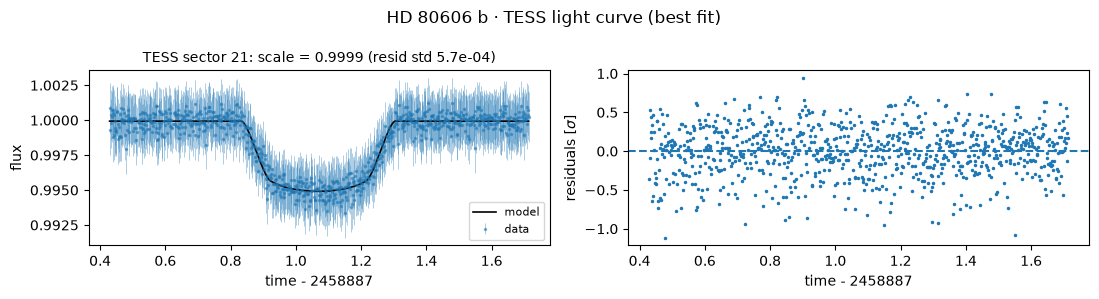

In [6]:
esl.plot.light_curve(fit);

## 4. Reading it

The depth here gives Rp/R★ ≈ 0.072, while ground-based and Spitzer measurements give about 0.10. The difference
is not the planet: TESS's large pixels also collect the light of HD 80607, a star of similar brightness 20″ away,
which makes every dip look shallower. That is **dilution**. If the other star adds a fraction d of the target's
light, the observed depth is the true depth / (1 + d); with d ≈ 1 the true Rp/R★ is about 0.072 × √2 ≈ 0.10.
The session can fit it: add a `dil` parameter (see the Methods page, "The likelihood").

In [7]:
r = fit.result["rprs"]
print(f"TESS Rp/R* = {r.median:.4f} +- {r.plus:.4f};  corrected for an equal-brightness neighbour: {r.median * np.sqrt(2):.3f}")

TESS Rp/R* = 0.0726 +- 0.0012;  corrected for an equal-brightness neighbour: 0.103


**Next:** [Lab 3](./lab03_radial_velocities) measures the planet's mass and orbit from the star's wobble.